# 서울 따릉이 1,021개 군집의 시간별 대여 수요

2024년 12월 현황에서 같은 군집 내 어느 두 대여소의 직선거리도 500m 이하가 되도록 묶은 2,766곳을 분석한다. 2023~2024년 각 시간에 군집 구성 대여소에서 **출발한 유효 대여 건수의 합**이 분석 단위다. 군집 안에서 출발해 같은 군집에 반납한 대여도 출발 한 건으로 센다.

2024년 12월의 구성을 고정해 과거를 되돌아본 결과다. 과거에는 존재했으나 12월 명단에 없는 번호는 별도로 집계한다. 기록이 없는 시간의 0건에는 개설 전·휴업 시간도 포함될 수 있다. 대여소당 평균을 계산할 때도 12월 명단의 대여소 수를 사용한다.

In [1]:
from pathlib import Path
import os
import subprocess
import sys
from tempfile import TemporaryDirectory
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "전처리/rental_aggregate.py").is_file())
OUT = ROOT / "모델"
stations = pd.read_csv(ROOT / "따릉이 대여소 비교/서울 전체 직선거리 500m 군집 배정.csv")
stations = stations.loc[stations["기준월"].eq("2024-12")].set_index("대여소번호").sort_index()
group = stations["완전연결 군집번호"]
ids = pd.Index(sorted(group.unique()), name="군집번호")
hours = pd.date_range("2023-01-01", "2025-01-01", freq="h", inclusive="left")
assert len(stations) == 2766 and group.index.is_unique and len(ids) == 1021
assert stations["완전연결 군집 내 최대거리(m)"].max() <= 500
plt.rcParams.update({"font.family": "Malgun Gothic" if os.name == "nt" else "sans-serif",
                     "axes.unicode_minus": False, "figure.dpi": 110})
print(f"{len(hours):,}시간 × {len(ids):,}개 군집 = {len(hours)*len(ids):,}개 군집·시간")

17,544시간 × 1,021개 군집 = 17,912,424개 군집·시간


## 월별 출발 건수를 군집에 배정

0분 또는 0m 대여를 제외하고 중복을 정리한 기존 전처리 집계를 사용한다. 원본 ZIP에서 다시 만들 때는 임시 폴더를 사용한다. 이미 만들어 둔 월별 집계 폴더가 있다면 환경변수 BIKE_AGGREGATE_CACHE로 지정할 수 있다. 매월 기존 서울 전체 합계와 50개 표본의 합계를 독립적으로 대조한다.

In [2]:
verified = pd.read_csv(ROOT / "전처리/월별 집계 검증.csv").set_index("월")
sample_ids = pd.read_csv(ROOT / "전처리/선정 대여소.csv").station_id
totals = np.zeros((len(hours), len(ids)), dtype=np.int32)
# 기준선에서 시차 대여량 중 예측 정시에 아직 반납이 확인되지 않은 건수를 뺀다.
late_returns = {lag: np.zeros_like(totals) for lag in (24, 168)}
# 각 출발 시간에 대해 1~24시간 후까지 확인된 누적 대여 건수를 저장한다.
confirmed = np.empty((len(hours), len(ids), 24), dtype=np.int16)
coverage = []
with TemporaryDirectory(prefix="cluster_demand_") as tmp:
    cached = os.environ.get("BIKE_AGGREGATE_CACHE")
    cache = Path(cached) if cached else Path(tmp)
    if not cached:
        subprocess.run([sys.executable, str(ROOT / "전처리/rental_aggregate.py"), str(cache)], check=True)
    for month, ref in verified.iterrows():
        start = hours.get_loc(pd.Timestamp(month))
        with np.load(cache / f"{month}.npz") as z:
            station_ids, counts = z["ids"], z["counts"]
        nh = counts.shape[1]
        assert nh == pd.Timestamp(month).days_in_month * 24
        assert counts.sum() == ref["집계 대여 건수"]
        assert counts[np.isin(station_ids, sample_ids)].sum() == ref["표본 50곳 대여 건수"]
        groups = group.reindex(station_ids)
        matched = groups.notna().to_numpy()
        cluster_idx = ids.get_indexer(groups[matched])
        np.add.at(totals[start:start+nh].T, cluster_idx, counts[matched])
        assigned = int(totals[start:start+nh].sum())
        assert assigned == counts[matched].sum()
        coverage.append((month, int(counts.sum()), assigned, int(counts[~matched].sum())))
        events = np.memmap(cache / f"{month}.bin", dtype="<i4", mode="r").reshape(-1, 3)
        assert len(events) == ref["필터 후 원천 행"] and np.count_nonzero(events[:,0]) == counts.sum()
        for lag, correction in late_returns.items():
            mask = (events[:,0] > 0) & (events[:,2] > events[:,1] + lag)
            delayed = events[mask, :2]
            positions = ids.get_indexer(group.reindex(delayed[:,0]))
            keep = (positions >= 0) & (delayed[:,1] + lag < len(hours))
            np.add.at(correction, (delayed[keep,1] + lag, positions[keep]), 1)
        # 반납 확인이 출발 다음 정시보다 늦은 대여만 지연 시간별로 센다.
        bins = np.zeros((26, nh, len(ids)), dtype=np.int32)
        for block_start in range(0, len(events), 250_000):
            block = events[block_start:block_start+250_000]
            delay = block[:,2] - block[:,1]
            delayed = (block[:,0] > 0) & (delay > 1)
            group_pos = ids.get_indexer(group.reindex(block[delayed,0]))
            keep = group_pos >= 0
            np.add.at(bins, (np.minimum(delay[delayed][keep],25),
                             block[delayed,1][keep] - start, group_pos[keep]), 1)
        pending = np.zeros((nh, len(ids)), dtype=np.int32)
        monthly_counts = totals[start:start+nh]
        assert monthly_counts.max() <= np.iinfo(np.int16).max
        for lag in range(24,0,-1):
            pending += bins[lag+1]
            as_known = monthly_counts - pending
            assert as_known.min() >= 0
            confirmed[start:start+nh,:,lag-1] = as_known
        del bins, block, events
demand = pd.DataFrame(totals, index=hours, columns=ids)
coverage = pd.DataFrame(coverage, columns=["월", "서울 전체", "군집 배정", "명단 외"])
assert len(coverage) == 24 and (coverage["서울 전체"] == coverage["군집 배정"] + coverage["명단 외"]).all()
annual = coverage.groupby(coverage["월"].str[:4])[["서울 전체", "군집 배정", "명단 외"]].sum()
annual["배정률(%)"] = 100 * annual["군집 배정"] / annual["서울 전체"]
display(annual.round(2))

,서울 전체,군집 배정,명단 외,배정률(%)
월,,,,
2023,43994125,42810716,1183409,97.31
2024,42688696,42219615,469081,98.90


## 2024년 수요가 많은 군집

군집 총량과 구성 대여소당 하루 평균을 따로 비교한다. 총량은 2024년의 합계이며, 대여소당 하루 평균은 총량을 366일과 12월 명단의 대여소 수로 나눈 값이다. 군집번호는 구성 대여소 번호 중 가장 작은 값이다.

In [3]:
members = stations.groupby("완전연결 군집번호")
summary = pd.DataFrame(index=ids)
summary["대여소 수"] = members.size()
summary["구성 대여소"] = members["대여소명"].agg(" · ".join)
summary["자치구"] = members["자치구"].agg(lambda values: " · ".join(sorted(set(values))))
for year in [2023, 2024]:
    summary[f"{year}년 출발 건수"] = demand.loc[str(year)].sum()
yearly = demand.loc["2024"]
days = yearly.index.normalize().nunique()
summary["2024년 대여소당 하루 평균"] = summary["2024년 출발 건수"] / (days * summary["대여소 수"])
assert days == 366 and summary["2024년 출발 건수"].sum() == annual.loc["2024","군집 배정"]
for metric in ["2024년 출발 건수", "2024년 대여소당 하루 평균"]:
    display(summary.nlargest(5, metric)[["자치구","구성 대여소","대여소 수",metric]].round(2))

,자치구,구성 대여소,대여소 수,2024년 출발 건수
군집번호,,,,
1198,강서구,LG 사이언스파크 · 마곡나루역 5번출구 뒤편 · 마곡나루역 2번 출구 · 마곡나루...,5,431024
1124,강서구,"발산역 6번 출구 뒤 · 발산역 1번, 9번 인근 대여소 · 마곡메가박스 앞 · 명...",8,344806
1151,강서구,마곡역1번출구 · 마곡역교차로 · 마곡역 교차로(2번출구) · 마곡역 버스정류장(마...,8,327560
247,영등포구,당산역 10번출구 앞 · 삼성화재 사옥 옆 · 그랜드컨벤션센터 앞 · 당산육갑문 ·...,5,235637
1210,송파구,롯데월드타워(잠실역2번출구 쪽) · 잠실역 6번출구 · 잠실역 8번출구 · 잠실 자...,4,226556


,자치구,구성 대여소,대여소 수,2024년 대여소당 하루 평균
군집번호,,,,
4217,마포구,한강공원 망원나들목,1,367.94
1198,강서구,LG 사이언스파크 · 마곡나루역 5번출구 뒤편 · 마곡나루역 2번 출구 · 마곡나루...,5,235.53
502,광진구,뚝섬유원지역 1번출구 앞 · 뚝섬 유원지역,2,215.24
2620,송파구,송파나루역 4번 출구옆 · 방이삼거리,2,180.30
207,영등포구,여의나루역 1번출구 앞 · LG트윈타워 앞,2,176.78


## 평일과 휴일의 시간대별 패턴

기상·달력 파일의 공휴일 표시를 사용해 주말·공휴일과 나머지 평일을 구분한다. 시간대별 평균의 분모는 해당 유형의 날짜 수다. 피크 시각은 0~23시 중 평균 출발 건수가 최대인 시간의 시작이며, 동률이면 빠른 시각이다.

평일 전체 군집 평균 피크 18시, 군집당 13.43건
주말·공휴일 전체 군집 평균 피크 17시, 군집당 7.22건


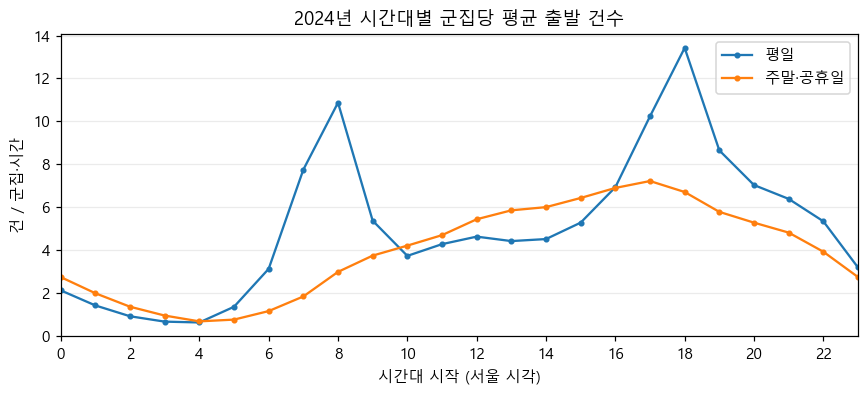

In [4]:
cal = pd.read_csv(ROOT / "분석용 데이터/Seoul_public_bicycle.csv", usecols=["datetime","holiday"],
                  parse_dates=["datetime"]).set_index("datetime")
holiday = cal.holiday.reindex(yearly.index)
assert holiday.isin([0,1]).all()
off = (yearly.index.weekday >= 5) | holiday.eq(1).to_numpy()
fig, ax = plt.subplots(figsize=(8,3.7))
for label, mask in [("평일", ~off), ("주말·공휴일", off)]:
    part = yearly.loc[mask]
    profile = part.groupby(part.index.hour).mean()
    summary[label + " 피크 시작시"] = profile.idxmax().where(profile.max() > 0).astype("Int64")
    avg = profile.mean(axis=1)
    ax.plot(avg.index, avg, label=label, marker="o", markersize=3)
    print(f"{label} 전체 군집 평균 피크 {avg.idxmax()}시, 군집당 {avg.max():.2f}건")
ax.set(title="2024년 시간대별 군집당 평균 출발 건수", xlabel="시간대 시작 (서울 시각)", ylabel="건 / 군집·시간",
       xticks=range(0,24,2), xlim=(0,23))
ax.grid(axis="y",alpha=.25)
ax.legend()
fig.tight_layout()
plt.show()
summary.to_csv(OUT / "1021개 군집별 대여 수요.csv", encoding="utf-8-sig", float_format="%.4f")

## 다음 1시간 대여량 예측의 기준선

각 군집에서 전날 같은 시간 또는 전주 같은 시간의 대여량을 그대로 예측값으로 사용한다. 당시까지 반납이 확인된 건수만 입력에 포함한다. 2024년 각 분기의 동일한 군집·시간 전체에서 비교한다. 오차 단위는 한 군집의 한 시간당 대여 건수다. 12월 군집을 사용했으므로 이 결과는 회고 비교로 해석한다.

In [5]:
scores = []
for lag in (24, 168):
    observed = totals[:-lag] - late_returns[lag][lag:]
    assert observed.min() >= 0
    dates = hours[lag:]
    for quarter in range(1,5):
        selected = (dates.year == 2024) & (dates.quarter == quarter)
        error = (totals[lag:][selected] - observed[selected]).astype("float64")
        scores.append([quarter, "전날 동일 시간" if lag == 24 else "전주 동일 시간",
                       error.size, np.abs(error).mean(), np.sqrt(np.square(error).mean())])
scores = pd.DataFrame(scores, columns=["분기","기준선","군집·시간 수","MAE","RMSE"])
assert scores.groupby("기준선")["군집·시간 수"].sum().eq(len(yearly)*len(ids)).all()
display(scores.pivot(index="분기",columns="기준선",values=["MAE","RMSE"]).round(3))

MAE              RMSE         
기준선 전날 동일 시간 전주 동일 시간 전날 동일 시간 전주 동일 시간
분기                                     
1      2.124    2.041    4.300    3.961
2      3.507    3.328    6.927    6.448
3      3.058    3.022    6.099    5.992
4      2.642    2.514    5.569    4.997

## MLP와 GRU로 각 군집의 다음 한 시간 예측

모델별로 1,021개 군집의 데이터를 함께 학습하고, 군집번호 임베딩으로 위치별 차이를 학습한다. 두 모델의 입력은 **직전 24시간의 군집별 출발량, 전주 동일 시간 출발량, 군집번호, 달력, 직전 시각의 기온·습도·강수량·풍속과 결측 표시**다. 각 과거 출발량은 해당 예측 정시 전 반납까지 확인된 값이다. MLP는 24개 값을 펼쳐 읽고 GRU는 오래된 순서부터 24번 읽는다.

이 실행은 군집 단위의 첫 비교다. 각 모델에 같은 MSE 손실, Adam 학습률 0.001, 배치 8,192, 4에포크, 시드 42를 적용한다. 에포크 수는 사전에 고정했다. 2024년 각 분기의 직전까지 매번 처음부터 학습한다. 학습 정답은 출발 후 24시간까지 확인된 값이며 학습 마감 시각까지 이 값이 준비된 행만 사용한다. 평가는 최종 유효 출발 건수로 한다. 개별 대여소 분석에서 사용한 반납량·유사 기상 피처는 이 실험의 입력에서 제외했다.

In [6]:
import torch
from torch import nn
import math

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH, EPOCHS, SEED = 8192, 4, 42
torch.set_num_threads(4)
torch.set_float32_matmul_precision("high")
N = len(ids)
deltas = torch.arange(24,0,-1,device=DEVICE)
np.testing.assert_array_equal(confirmed[:-24,:,23], totals[:-24] - late_returns[24][24:])
weekly = np.zeros_like(totals)
weekly[168:] = totals[:-168] - late_returns[168][168:]
assert weekly.min() >= 0 and weekly.max() <= np.iinfo(np.int16).max
past = torch.as_tensor(confirmed, device=DEVICE)
week = torch.as_tensor(weekly.astype(np.int16), device=DEVICE)
actual = torch.as_tensor(totals, device=DEVICE)
weather_names = ["temperature","humidity","precipitation","windspeed"]
wx = pd.read_csv(ROOT / "분석용 데이터/Seoul_public_bicycle.csv",parse_dates=["datetime"]).set_index("datetime")
w = wx[weather_names].reindex(hours - pd.Timedelta(hours=1)).to_numpy(dtype="float32")
fixed = np.column_stack([np.eye(24)[hours.hour], np.eye(7)[hours.weekday],
                         np.eye(12)[hours.month-1], wx.holiday.loc[hours].to_numpy()]).astype("float32")
def context_at(cutoff):
    reference = w[168:cutoff-23]
    median = np.nanmedian(reference,axis=0)
    reference = np.where(np.isnan(reference),median,reference)
    mean, std = reference.mean(axis=0), reference.std(axis=0).clip(1e-6)
    values = (np.where(np.isnan(w),median,w)-mean)/std
    combined = np.column_stack([fixed,values,np.isnan(w)])
    assert np.isfinite(combined).all()
    return torch.as_tensor(combined,device=DEVICE), {"median":median.tolist(),"mean":mean.tolist(),"std":std.tolist()}

def batch_inputs(flat):
    t = flat // N
    g = flat % N
    seq = past[t[:,None]-deltas,g[:,None],deltas-1].float().log1p()
    weekly_value = week[t,g].float().log1p().unsqueeze(1)
    return t, g, seq, weekly_value

class ClusterNet(nn.Module):
    def __init__(self, kind, context_size):
        super().__init__()
        self.embedding = nn.Embedding(N, 8)
        self.gru = nn.GRU(1,16,batch_first=True) if kind == "GRU" else None
        history_size = 16 if self.gru is not None else 24
        self.head = nn.Sequential(nn.Linear(history_size + context_size + 8 + 1, 64), nn.ReLU(),
                                  nn.Linear(64,32), nn.ReLU(), nn.Linear(32,1), nn.Softplus())

    def forward(self, seq, weekly_value, context, g):
        history = seq
        if self.gru is not None:
            _, hidden = self.gru(seq.unsqueeze(-1))
            history = hidden[-1]
        features = torch.cat([history,weekly_value,context,self.embedding(g)],dim=1)
        return self.head(features).squeeze(1)

print(f"학습 장치 {DEVICE}, 군집 {N:,}개")

학습 장치 cuda, 군집 1,021개


In [7]:
def train_model(kind, cutoff, context):
    torch.manual_seed(SEED)
    model = ClusterNet(kind, context.shape[1]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
    loss_fn = nn.MSELoss()
    # t + 24 <= cutoff이고 전주 동일 시간 관측이 있는 모든 학습 행을 사용한다.
    n_rows = (cutoff - 23 - 168) * N
    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(n_rows,device=DEVICE)
        for ix in order.split(BATCH):
            t,g,seq,wk = batch_inputs(ix + 168*N)
            pred = model(seq,wk,context[t],g)
            loss = loss_fn(pred,past[t,g,23].float())
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5.)
            optimizer.step()
        print(f"{kind} {epoch+1}/{EPOCHS}에포크 완료",flush=True)
    return model

@torch.inference_mode()
def evaluate(model, start, stop, context):
    model.eval()
    sums = torch.zeros(2,device=DEVICE,dtype=torch.float64)
    for begin in range(start*N,stop*N,BATCH):
        flat = torch.arange(begin,min(stop*N,begin+BATCH),device=DEVICE)
        t,g,seq,wk = batch_inputs(flat)
        err = (model(seq,wk,context[t],g) - actual[t,g]).double()
        sums += torch.stack([err.abs().sum(),err.square().sum()])
    n_rows = (stop-start)*N
    mae, mse = (sums/n_rows).cpu().tolist()
    assert math.isfinite(mae) and math.isfinite(mse)
    return n_rows, mae, math.sqrt(mse)

In [8]:
neural = []
for quarter, begin in enumerate(pd.date_range("2024-01-01","2024-10-01",freq="QS"),1):
    start = int(hours.searchsorted(begin))
    stop = int(hours.searchsorted(begin + pd.DateOffset(months=3)))
    context, scaling = context_at(start)
    for kind in ("MLP","GRU"):
        print(f"{quarter}분기 {kind} 학습",flush=True)
        model = train_model(kind,start,context)
        size,mae,rmse = evaluate(model,start,stop,context)
        neural.append([quarter,kind,size,mae,rmse])
        print(f"{quarter}분기 {kind} MAE {mae:.4f}, RMSE {rmse:.4f}",flush=True)
        if quarter == 4:
            torch.save({"kind":kind,"weights":model.cpu().state_dict(),"cluster_ids":list(map(int,ids)),
                        "context_size":context.shape[1],"weather":weather_names,"scaling":scaling,
                        "seed":SEED,"epochs":EPOCHS,"cutoff":str(begin)}, OUT / f"cluster1021_{kind.lower()}.pt")
        del model
comparison = pd.concat([scores.rename(columns={"기준선":"모델"}),
                        pd.DataFrame(neural,columns=["분기","모델","군집·시간 수","MAE","RMSE"])],ignore_index=True)
assert comparison.groupby("분기")["군집·시간 수"].nunique().eq(1).all()
display(comparison.pivot(index="분기",columns="모델",values="MAE").round(4))
display(comparison.pivot(index="분기",columns="모델",values="RMSE").round(4))
comparison.to_csv(OUT/"1021개 군집 예측 성능.csv",index=False,encoding="utf-8-sig")

1분기 MLP 학습


MLP 1/4에포크 완료


MLP 2/4에포크 완료


MLP 3/4에포크 완료


MLP 4/4에포크 완료


1분기 MLP MAE 1.4603, RMSE 2.5291


... (40 outputs left out)

GRU 4/4에포크 완료


4분기 GRU MAE 1.7265, RMSE 2.9410


모델,GRU,MLP,전날 동일 시간,전주 동일 시간
분기,,,,
1,1.4429,1.4603,2.1240,2.0407
2,2.2122,2.2868,3.5072,3.3276
3,2.0680,2.0086,3.0582,3.0222
4,1.7265,1.7806,2.6423,2.5136


모델,GRU,MLP,전날 동일 시간,전주 동일 시간
분기,,,,
1,2.5232,2.5291,4.3000,3.9615
2,3.8293,3.8826,6.9273,6.4483
3,3.4969,3.5310,6.0993,5.9917
4,2.9410,3.0744,5.5689,4.9967
